# Assignment 3: controlled improvement experiments

This notebook tests a specific hypothesis: mild variation in feature proportions may improve generalisation when image shapes differ between training and test data. **No improvement has been measured yet.** Preserve the existing submission that scored 0.9785.

**First run:** attach your original competition data, enable a Kaggle GPU and Internet for pretrained weights, then Run All. The two default experiments use the same split, model, optimiser and eight-epoch budget. Only the new shape augmentation differs. The notebook never submits to Kaggle automatically.

The audit uses test image dimensions only. Test labels are unavailable and the sample submission's class values are placeholders. No manual labelling, test-label inference or external dataset is used. Pretrained models are allowed by the brief.

The original 85/15 split is retained for comparison. Exact duplicates are removed, but related crops may still cross the split: source-photo independence is **not** established. Synthetic stress scores are diagnostic probes, not estimates of Kaggle accuracy. A second split must be trained from scratch to confirm a candidate.


In [1]:
from pathlib import Path
import os, json, random, hashlib, math, time, copy, platform
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
import timm
from timm.data import resolve_model_data_config
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss, classification_report, confusion_matrix
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

# Set BASE to a folder containing train_labels.csv and sample_submission.csv
# only if automatic discovery finds more than one valid dataset.
BASE = None
OUT = Path('/kaggle/working/confirmation_split1337')
OUT.mkdir(parents=True, exist_ok=True)
SPLIT_SEED = 1337      # Original split. Use 1337 for a separate confirmation session.
TRAIN_SEED = 42
VAL_FRACTION = 0.15
NUM_WORKERS = 2
BATCH_SIZE = 128
FULL_DATA = False    # Keep False for experiments. See final cell before changing.
FULL_EPOCHS = None   # Set only after selecting an epoch budget using validation.

# Start with this pair. Do not change several settings within the pair.
RUNS = ['control_128', 'geometry_128']
# Later: ['control_192', 'geometry_192'] for a resolution comparison.
# Later: ['efficientnet_192'] to test a different architecture.
EXPERIMENTS = {
    'control_128': dict(model='convnext_tiny', size=128, geometry=False),
    'geometry_128': dict(model='convnext_tiny', size=128, geometry=True),
    'control_192': dict(model='convnext_tiny', size=192, geometry=False),
    'geometry_192': dict(model='convnext_tiny', size=192, geometry=True),
    'efficientnet_192': dict(model='tf_efficientnetv2_s', size=192, geometry=True),
}
COMMON = dict(epochs=8, lr=3e-4, weight_decay=0.05,
              label_smoothing=0.1, downscale_p=0.3)
assert torch.cuda.is_available(), 'Enable a Kaggle GPU before running training.'
assert not FULL_DATA or (isinstance(FULL_EPOCHS, int) and FULL_EPOCHS > 0), 'Choose FULL_EPOCHS first.'
assert len(RUNS) == len(set(RUNS)) and all(x in EXPERIMENTS for x in RUNS)
device = torch.device('cuda')
versions = dict(python=platform.python_version(), torch=torch.__version__,
                torchvision=torchvision.__version__, timm=timm.__version__)
print('GPU:', torch.cuda.get_device_name(0), '| versions:', versions)
(OUT/'versions.json').write_text(json.dumps(versions, indent=2))

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed); random.seed(worker_seed)


GPU: Tesla T4 | versions: {'python': '3.13.15', 'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'timm': '1.0.29'}


## 1. Locate and audit the original data
The training metadata cache is tied to the label-file hash and dataset path. If you replace images at the same path, delete the cache and rerun the audit. The original archive is expected to contain 63,660 training images and 29,443 test images.


In [2]:
def image_folder(base, kind):
    for candidate in [base/kind/kind, base/kind]:
        if (candidate/'00001.jpg').is_file():
            return candidate
    raise FileNotFoundError(f'Cannot find {kind} images below {base}')

if BASE is None:
    candidates = []
    for p in Path('/kaggle/input').rglob('train_labels.csv'):
        if not (p.parent/'sample_submission.csv').is_file(): continue
        try:
            image_folder(p.parent, 'train'); image_folder(p.parent, 'test')
            candidates.append(p.parent)
        except FileNotFoundError:
            pass
    assert len(candidates) == 1, f'Set BASE explicitly; valid dataset roots: {candidates}'
    BASE = candidates[0]
BASE = Path(BASE)
TRAIN_DIR, TEST_DIR = image_folder(BASE, 'train'), image_folder(BASE, 'test')
labels = pd.read_csv(BASE/'train_labels.csv')
sample = pd.read_csv(BASE/'sample_submission.csv')
CLASSES = ['CatEye','CatFace','CatMouth','CatNose','DogEye','DogFace','DogMouth','DogNose']
CLASS_TO_IDX = {c:i for i,c in enumerate(CLASSES)}
assert list(labels.columns) == ['image_id','class']
assert list(sample.columns) == ['image_id','class']
assert len(labels) == 63660 and len(sample) == 29443
assert labels.image_id.is_unique and sample.image_id.is_unique
assert not labels.isna().any().any() and not sample.image_id.isna().any()
assert set(labels['class']) == set(CLASSES)
label_sha = hashlib.sha256((BASE/'train_labels.csv').read_bytes()).hexdigest()
audit_key = hashlib.sha256((str(BASE)+label_sha).encode()).hexdigest()[:16]
cache = OUT/f'train_metadata_{audit_key}.csv'
if cache.exists():
    meta = pd.read_csv(cache)
    assert meta.image_id.tolist() == labels.image_id.tolist()
    assert meta['class'].tolist() == labels['class'].tolist()
else:
    rows = []
    for img_id, cls in tqdm(zip(labels.image_id, labels['class']), total=len(labels), desc='Audit training images'):
        path = TRAIN_DIR/f'{int(img_id):05d}.jpg'
        raw = path.read_bytes()
        with Image.open(path) as im:
            im.load()  # Decode fully: fail visibly on unreadable images.
            w,h = im.size
        rows.append(dict(image_id=int(img_id), **{'class':cls},
                         width=w, height=h, aspect=round(w/h,2),
                         md5=hashlib.md5(raw).hexdigest()))
    meta = pd.DataFrame(rows)
    meta.to_csv(cache, index=False)
assert len(meta) == len(labels)
assert (meta['class'].to_numpy() == labels['class'].to_numpy()).all()
conflicts = meta.groupby('md5')['class'].nunique()
assert conflicts.max() == 1, 'Conflicting duplicate labels need review before training.'
df = meta.drop_duplicates('md5', keep='first').reset_index(drop=True).copy()
df['label'] = df['class'].map(CLASS_TO_IDX)
assert len(df) == 63645, f'Unexpected cleaned dataset size: {len(df)}'
print('Dataset:', BASE, '| unique training images:', len(df))
print(df['class'].value_counts().sort_index())


Audit training images:   0%|          | 0/63660 [00:00<?, ?it/s]

Dataset: /kaggle/input/datasets/khlafalshammari/competition | unique training images: 63645
class
CatEye      13877
CatFace      6942
CatMouth     6941
CatNose      6941
DogEye      11576
DogFace      5788
DogMouth     5790
DogNose      5790
Name: count, dtype: int64


In [3]:
# Unlabelled test aggregate dimensions only; never use placeholder classes as labels.
test_meta_path = OUT/f'test_dimensions_{audit_key}.csv'
if test_meta_path.exists():
    test_meta = pd.read_csv(test_meta_path)
else:
    dims = []
    for image_id in tqdm(sample.image_id, desc='Audit test dimensions'):
        with Image.open(TEST_DIR/f'{int(image_id):05d}.jpg') as im:
            w,h = im.size
        dims.append(dict(image_id=int(image_id), width=w, height=h, aspect=round(w/h,2)))
    test_meta = pd.DataFrame(dims)
    test_meta.to_csv(test_meta_path, index=False)
assert test_meta.image_id.tolist() == sample.image_id.tolist()
def dimension_summary(frame):
    a = frame.aspect
    return pd.Series({'images':len(frame), 'near_square_pct':100*((a-1).abs()<.05).mean(),
                      'tall_pct':100*(a<.9).mean(), 'wide_pct':100*(a>=1.25).mean(),
                      'under32_pct':100*(frame[['width','height']].min(axis=1)<32).mean()})
shape_summary = pd.DataFrame({'train':dimension_summary(df), 'test':dimension_summary(test_meta)})
shape_summary.to_csv(OUT/'shape_summary.csv')
print(shape_summary.round(2))

train_df, val_df = train_test_split(df, test_size=VAL_FRACTION,
                                  stratify=df.label, random_state=SPLIT_SEED)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
assert set(train_df.md5).isdisjoint(set(val_df.md5))
assert set(train_df.image_id).isdisjoint(set(val_df.image_id))
split_hash = hashlib.sha256(val_df.image_id.to_numpy(dtype='<i8').tobytes()).hexdigest()
train_df[['image_id','class']].to_csv(OUT/f'train_split_{SPLIT_SEED}.csv', index=False)
val_df[['image_id','class']].to_csv(OUT/f'val_split_{SPLIT_SEED}.csv', index=False)
print('Train / validation:', len(train_df), len(val_df), '| validation ID hash:', split_hash)


Audit test dimensions:   0%|          | 0/29443 [00:00<?, ?it/s]

                    train      test
images           63645.00  29443.00
near_square_pct     69.89     44.57
tall_pct             7.36     16.33
wide_pct            20.37     22.78
under32_pct          6.49      8.23
Train / validation: 54098 9547 | validation ID hash: 842af9ee7beb6fe8c85fd55163deeb15cf8a5c778506c075f987e9b9ed9889b6


## 2. Controlled transforms

Both experiments keep the original resize, flip, mild affine, colour jitter and downscaling settings. The candidate additionally pads each axis by a random small amount and resizes back to a square. This varies feature proportions without deliberately cutting away the original crop. Reflected borders are artificial, so this augmentation must earn its place through experiments.

The deterministic `wide` and `tall` validation views are synthetic stress tests of the same idea. They do not reproduce a known test-generation process. Normalisation is read from each pretrained model's configuration and saved with the checkpoint; it is used consistently for training and inference.


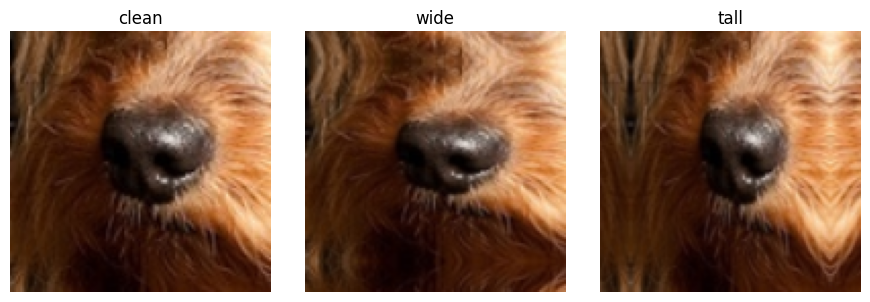

In [4]:
class RandomDownscale:
    def __init__(self, p=.3): self.p=p
    def __call__(self, img):
        if random.random() < self.p:
            target=random.randint(16,48); short=min(img.size)
            if short > target:
                scale=target/short
                img=img.resize((max(1,round(img.width*scale)), max(1,round(img.height*scale))),
                               Image.Resampling.BILINEAR)
        return img

class AxisPad:
    def __init__(self, p=.5, max_fraction=.15, fixed=None):
        self.p, self.max_fraction, self.fixed = p, max_fraction, fixed
    def __call__(self, img):
        if self.fixed is None:
            if random.random() >= self.p: return img
            fx=random.uniform(0,self.max_fraction)
            fy=random.uniform(0,self.max_fraction)
        else:
            fx,fy=self.fixed
        w,h=img.size
        px,py=round(w*fx),round(h*fy)
        # This runs after square resizing: padding is always smaller than either side.
        return TF.pad(img, [px,py,px,py], padding_mode='reflect')

def transforms_for(cfg, training=False, stress=None):
    s=cfg['size']; ops=[]
    if training: ops.append(RandomDownscale(cfg['downscale_p']))
    ops.append(T.Resize((s,s), interpolation=T.InterpolationMode.BILINEAR, antialias=True))
    if training and cfg['geometry']:
        ops.extend([AxisPad(), T.Resize((s,s), antialias=True)])
    if stress:
        fixed={'wide':(0,.15), 'tall':(.15,0)}[stress]
        ops.extend([AxisPad(fixed=fixed), T.Resize((s,s), antialias=True)])
    if training:
        ops.extend([T.RandomHorizontalFlip(.5),
                    T.RandomAffine(degrees=10, translate=(.05,.05), scale=(.9,1.1)),
                    T.ColorJitter(brightness=.3, contrast=.3, saturation=.2)])
    ops.extend([T.ToTensor(), T.Normalize(cfg['mean'],cfg['std'])])
    return T.Compose(ops)

class Images(Dataset):
    def __init__(self, frame, folder, transform):
        self.frame=frame.reset_index(drop=True); self.folder=folder; self.transform=transform
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]; image_id=int(r['image_id'])
        with Image.open(self.folder/f'{image_id:05d}.jpg') as im:
            x=self.transform(im.convert('RGB'))
        y=int(r['label']) if 'label' in self.frame.columns else -1
        return x,y,image_id

def loader_for(frame, folder, cfg, training=False, stress=None):
    return DataLoader(Images(frame,folder,transforms_for(cfg,training,stress)),
                      batch_size=BATCH_SIZE, shuffle=training, drop_last=False,
                      num_workers=NUM_WORKERS, pin_memory=True,
                      persistent_workers=NUM_WORKERS>0, worker_init_fn=seed_worker,
                      generator=torch.Generator().manual_seed(TRAIN_SEED))

# Check one labelled training image; this preview does not consume the training loader.
preview_cfg={**COMMON, **EXPERIMENTS['geometry_128'],
             'mean':[.485,.456,.406], 'std':[.229,.224,.225]}
seed_all(TRAIN_SEED)
r=train_df.iloc[0]
with Image.open(TRAIN_DIR/f'{int(r.image_id):05d}.jpg') as im:
    source=im.convert('RGB')
    fig,axs=plt.subplots(1,3,figsize=(9,3))
    for ax,kind in zip(axs,['clean','wide','tall']):
        tf=transforms_for(preview_cfg,stress=None if kind=='clean' else kind)
        x=tf(source); mean=torch.tensor(preview_cfg['mean'])[:,None,None]
        std=torch.tensor(preview_cfg['std'])[:,None,None]
        ax.imshow((x*std+mean).clamp(0,1).permute(1,2,0)); ax.set_title(kind); ax.axis('off')
plt.tight_layout(); plt.show()


## 3. Training and evaluation

The eight-epoch budget is fixed for both runs. Checkpoints are selected by clean validation accuracy, with ordinary cross-entropy as the tie breaker. Training loss uses label smoothing; `val_nll` does not, so these are different quantities. The scheduler advances only when mixed precision actually makes an optimiser update. Each checkpoint records classes, normalisation, split provenance and settings.

Expect small numerical differences from the earlier notebooks: this is a fresh control run, not bit-for-bit reproduction. It also keeps the last partial training batch rather than dropping it. No claim of full determinism across hardware or package versions is made.


In [5]:
@torch.inference_mode()
def predict(model, loader, flip=False):
    model.eval(); probs=[]; labels_out=[]; ids=[]
    for x,y,image_ids in loader:
        x=x.to(device,non_blocking=True)
        with torch.autocast('cuda',dtype=torch.float16):
            logits=model(x)
        p=logits.float().softmax(1)
        if flip:
            with torch.autocast('cuda',dtype=torch.float16):
                flipped=model(torch.flip(x,[3]))
            p=(p+flipped.float().softmax(1))/2
        probs.append(p.cpu().numpy()); labels_out.append(y.numpy()); ids.append(image_ids.numpy())
    return np.concatenate(probs),np.concatenate(labels_out),np.concatenate(ids)

def metrics(y,p):
    assert p.shape == (len(y),len(CLASSES))
    assert np.isfinite(p).all() and np.allclose(p.sum(1),1,atol=1e-5)
    return {'accuracy':float(accuracy_score(y,p.argmax(1))),
            'nll':float(log_loss(y,p,labels=np.arange(len(CLASSES)))),
            'errors':int((p.argmax(1)!=y).sum())}

def fit(cfg, run_dir):
    seed_all(TRAIN_SEED)
    model=timm.create_model(cfg['model'],pretrained=True,num_classes=len(CLASSES)).to(device)
    data_cfg=resolve_model_data_config(model)
    cfg=copy.deepcopy(cfg)
    cfg['mean']=list(data_cfg['mean']); cfg['std']=list(data_cfg['std'])
    cfg.update(split_seed=SPLIT_SEED, train_seed=TRAIN_SEED, full_data=FULL_DATA,
               classes=CLASSES, label_sha256=label_sha, split_hash=None if FULL_DATA else split_hash,
               versions=versions)
    train_frame=df if FULL_DATA else train_df
    train_loader=loader_for(train_frame,TRAIN_DIR,cfg,training=True)
    val_loader=None if FULL_DATA else loader_for(val_df,TRAIN_DIR,cfg)
    epochs=FULL_EPOCHS if FULL_DATA else cfg['epochs']
    cfg['actual_epochs']=epochs
    (run_dir/'config.json').write_text(json.dumps(cfg,indent=2))
    opt=torch.optim.AdamW(model.parameters(),lr=cfg['lr'],weight_decay=cfg['weight_decay'])
    total_steps=epochs*len(train_loader); warmup_steps=len(train_loader)
    def schedule(step):
        if step<warmup_steps:return (step+1)/warmup_steps
        progress=(step-warmup_steps)/max(1,total_steps-warmup_steps)
        return .5*(1+math.cos(math.pi*min(progress,1)))
    scheduler=torch.optim.lr_scheduler.LambdaLR(opt,schedule)
    scaler=torch.amp.GradScaler('cuda')
    criterion=nn.CrossEntropyLoss(label_smoothing=cfg['label_smoothing'])
    history=[]; best=(-1.,-float('inf')); best_path=run_dir/'best.pth'
    skipped=0
    for epoch in range(1,epochs+1):
        start=time.time(); model.train(); loss_sum=0.; correct=0; n=0
        for x,y,_ in tqdm(train_loader,desc=f'{run_dir.name} epoch {epoch}/{epochs}',leave=False):
            x=x.to(device,non_blocking=True);y=y.to(device,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda',dtype=torch.float16):
                logits=model(x);loss=criterion(logits,y)
            scale_before=scaler.get_scale()
            scaler.scale(loss).backward();scaler.step(opt);scaler.update()
            if scaler.get_scale()>=scale_before:scheduler.step()
            else:skipped+=1
            loss_sum+=loss.item()*len(y);correct+=(logits.argmax(1)==y).sum().item();n+=len(y)
        row=dict(epoch=epoch,train_loss=loss_sum/n,train_acc=correct/n,
                 skipped_updates=skipped,seconds=round(time.time()-start,1))
        if not FULL_DATA:
            p,y,ids=predict(model,val_loader)
            assert np.array_equal(ids,val_df.image_id.to_numpy())
            m=metrics(y,p);row.update(val_acc=m['accuracy'],val_nll=m['nll'],val_errors=m['errors'])
            rank=(m['accuracy'],-m['nll'])
            save=rank>best
            if save:best=rank
        else:
            save=True # Save the latest epoch; there is deliberately no validation score.
        if save:
            torch.save({'model':model.state_dict(),'config':cfg,'epoch':epoch,
                        'validation':None if FULL_DATA else m},best_path)
        history.append(row);pd.DataFrame(history).to_csv(run_dir/'history.csv',index=False)
        print(row)
    del train_loader,val_loader
    checkpoint=torch.load(best_path,map_location='cpu',weights_only=False)
    model.load_state_dict(checkpoint['model'])
    print('Loaded checkpoint epoch',checkpoint['epoch'])
    return model,cfg,pd.DataFrame(history)


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

control_128_val1337_seed42 epoch 1/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.6680208019260259, 'train_acc': 0.9133054826426116, 'skipped_updates': 5, 'seconds': 1051.9, 'val_acc': 0.9772703467057714, 'val_nll': 0.15118849090116557, 'val_errors': 217}


control_128_val1337_seed42 epoch 2/8:   0%|          | 0/423 [00:00<?, ?it/s]

...

{'epoch': 6, 'train_loss': 0.47486946342736147, 'train_acc': 0.9966357351473252, 'skipped_updates': 5, 'seconds': 109.0, 'val_acc': 0.9969623965643658, 'val_nll': 0.10105526496478985, 'val_errors': 29}


control_128_val1337_seed42 epoch 7/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.4708893514150189, 'train_acc': 0.9983918074605346, 'skipped_updates': 5, 'seconds': 110.0, 'val_acc': 0.9972766314025349, 'val_nll': 0.09933722446774733, 'val_errors': 26}


control_128_val1337_seed42 epoch 8/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.4694438069500215, 'train_acc': 0.9990942363858183, 'skipped_updates': 5, 'seconds': 110.1, 'val_acc': 0.9971718864564785, 'val_nll': 0.09923531904881028, 'val_errors': 27}
Loaded checkpoint epoch 7


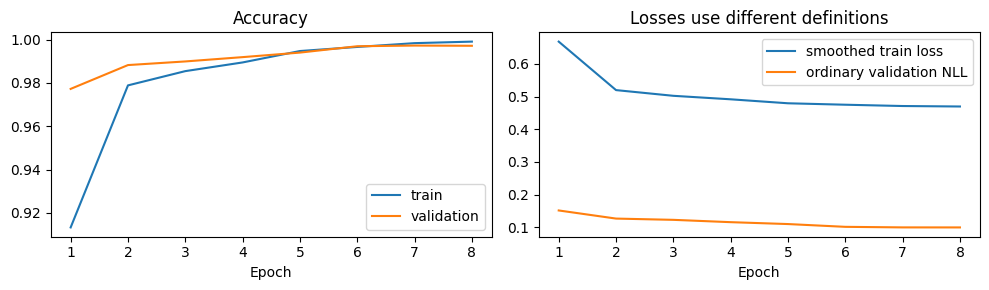

geometry_128_val1337_seed42 epoch 1/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.6792988508059413, 'train_acc': 0.909460608525269, 'skipped_updates': 5, 'seconds': 130.1, 'val_acc': 0.9811459097098565, 'val_nll': 0.13769357117492992, 'val_errors': 180}


geometry_128_val1337_seed42 epoch 2/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.527828416368993, 'train_acc': 0.975026803208991, 'skipped_updates': 5, 'seconds': 130.6, 'val_acc': 0.9884780559338012, 'val_nll': 0.12268198737398996, 'val_errors': 110}


geometry_128_val1337_seed42 epoch 3/8:   0%|          | 0/423 [00:00<?, ?it/s]

...

{'epoch': 6, 'train_loss': 0.47720819278461285, 'train_acc': 0.9954342119856556, 'skipped_updates': 5, 'seconds': 171.6, 'val_acc': 0.9965434167801404, 'val_nll': 0.1026030353332883, 'val_errors': 33}


geometry_128_val1337_seed42 epoch 7/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.47189801753111577, 'train_acc': 0.9979481681393028, 'skipped_updates': 5, 'seconds': 388.3, 'val_acc': 0.9959149471038022, 'val_nll': 0.10179476386884037, 'val_errors': 39}


geometry_128_val1337_seed42 epoch 8/8:   0%|          | 0/423 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.4701746066714696, 'train_acc': 0.9986136271211505, 'skipped_updates': 5, 'seconds': 578.5, 'val_acc': 0.9963339268880277, 'val_nll': 0.10108617526984126, 'val_errors': 35}
Loaded checkpoint epoch 6


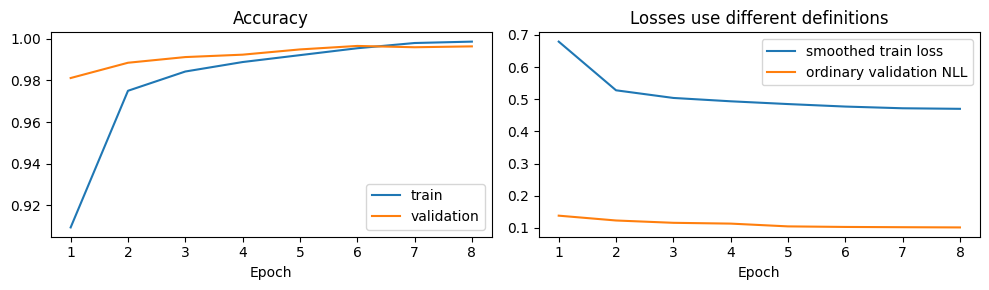

accuracy                                    errors  \
view             clean clean_flip_tta      tall      wide  clean   
run                                                                
control_128   0.997277       0.997277  0.886456  0.987221   26.0   
geometry_128  0.996543       0.996962  0.992877  0.991411   33.0   

                                            
view         clean_flip_tta    tall   wide  
run                                         
control_128            26.0  1084.0  122.0  
geometry_128           29.0    68.0   82.0

Saved outputs: /kaggle/working/confirmation_split1337


In [6]:
def save_probabilities(path, probs, ids, y=None):
    payload=dict(probs=probs,image_id=ids,classes=np.array(CLASSES),
                 split_hash=np.array('full_data' if FULL_DATA else split_hash))
    if y is not None: payload['labels']=y
    np.savez_compressed(path,**payload)

def save_submission(path,probs,ids):
    assert np.array_equal(ids,sample.image_id.to_numpy()), 'Prediction ID order mismatch'
    assert probs.shape==(len(sample),len(CLASSES)) and np.isfinite(probs).all()
    assert (probs>=0).all() and np.allclose(probs.sum(1),1,atol=1e-5)
    sub=sample.copy()
    sub['class']=np.array(CLASSES)[probs.argmax(1)]
    assert sub.image_id.is_unique and not sub.isna().any().any()
    sub.to_csv(path,index=False)

results=[]; run_outputs={}
mode='full' if FULL_DATA else f'val{SPLIT_SEED}'
for name in RUNS:
    run_dir=OUT/f'{name}_{mode}_seed{TRAIN_SEED}'
    assert not run_dir.exists(), f'{run_dir} already exists; use another output folder to preserve prior runs.'
    run_dir.mkdir(parents=True)
    cfg={**COMMON,**EXPERIMENTS[name]}
    model,cfg,hist=fit(cfg,run_dir)
    fig,axs=plt.subplots(1,2,figsize=(10,3))
    axs[0].plot(hist.epoch,hist.train_acc,label='train')
    if not FULL_DATA:axs[0].plot(hist.epoch,hist.val_acc,label='validation')
    axs[0].set_title('Accuracy');axs[0].legend();axs[0].set_xlabel('Epoch')
    axs[1].plot(hist.epoch,hist.train_loss,label='smoothed train loss')
    if not FULL_DATA:axs[1].plot(hist.epoch,hist.val_nll,label='ordinary validation NLL')
    axs[1].set_title('Losses use different definitions');axs[1].legend();axs[1].set_xlabel('Epoch')
    plt.tight_layout();fig.savefig(run_dir/'learning_curves.png',dpi=140);plt.show();plt.close(fig)
    if not FULL_DATA:
        for view in ['clean','wide','tall']:
            loader=loader_for(val_df,TRAIN_DIR,cfg,stress=None if view=='clean' else view)
            p,y,ids=predict(model,loader,flip=False)
            save_probabilities(run_dir/f'val_{view}.npz',p,ids,y)
            results.append(dict(run=name,view=view,**metrics(y,p)))
            if view=='clean':
                report=classification_report(y,p.argmax(1),labels=range(len(CLASSES)),
                                             target_names=CLASSES,digits=5,zero_division=0)
                (run_dir/'classification_report.txt').write_text(report)
                pd.DataFrame(confusion_matrix(y,p.argmax(1),labels=range(len(CLASSES))),
                             index=CLASSES,columns=CLASSES).to_csv(run_dir/'confusion_matrix.csv')
                errors=val_df.copy();errors['pred_class']=np.array(CLASSES)[p.argmax(1)]
                errors=errors[errors['class']!=errors.pred_class]
                errors.to_csv(run_dir/'validation_errors.csv',index=False)
            del loader
        p,y,ids=predict(model,loader_for(val_df,TRAIN_DIR,cfg),flip=True)
        save_probabilities(run_dir/'val_tta.npz',p,ids,y)
        results.append(dict(run=name,view='clean_flip_tta',**metrics(y,p)))
    # Save original and flip-averaged test probabilities with authoritative IDs.
    test_loader=loader_for(sample[['image_id']],TEST_DIR,cfg)
    p,_,ids=predict(model,test_loader,flip=False)
    save_probabilities(run_dir/'test_clean.npz',p,ids)
    save_submission(run_dir/'submission_clean.csv',p,ids)
    p,_,ids=predict(model,test_loader,flip=True)
    save_probabilities(run_dir/'test_tta.npz',p,ids)
    save_submission(run_dir/'submission_tta.csv',p,ids)
    del test_loader,model;torch.cuda.empty_cache()
    run_outputs[name]=run_dir
    if results:pd.DataFrame(results).to_csv(OUT/'experiment_results.csv',index=False)
if results:
    display(pd.DataFrame(results).pivot(index='run',columns='view',values=['accuracy','errors']))
print('Saved outputs:',OUT)


## 4. Compare paired errors before choosing a model

A gain of a few images on a repeatedly used split is weak evidence. This table shows which predictions changed, including correct predictions that a candidate broke. If the candidate looks promising, repeat the **control and candidate training** in a new session with `SPLIT_SEED=1337`. Existing models must not be evaluated on a newly chosen holdout if they trained on those images.

Keep GPU and package settings constant for comparisons. The confirmation split can still contain related crops, so it tests split sensitivity rather than proving source-independent generalisation. Report this limitation.


In [7]:
if not FULL_DATA:
    for control,candidate in [('control_128','geometry_128'),('control_192','geometry_192')]:
        if control not in run_outputs or candidate not in run_outputs:continue
        paired=[]
        for view in ['clean','wide','tall','tta']:
            a=np.load(run_outputs[control]/f'val_{view}.npz')
            b=np.load(run_outputs[candidate]/f'val_{view}.npz')
            assert np.array_equal(a['image_id'],b['image_id'])
            assert np.array_equal(a['labels'],b['labels'])
            y=a['labels'];pa=a['probs'].argmax(1);pb=b['probs'].argmax(1)
            paired.append(dict(view=view,control_errors=int((pa!=y).sum()),
                               candidate_errors=int((pb!=y).sum()),
                               fixed=int(((pa!=y)&(pb==y)).sum()),
                               broken=int(((pa==y)&(pb!=y)).sum())))
        comparison=pd.DataFrame(paired)
        comparison.to_csv(OUT/f'paired_{control}_{candidate}.csv',index=False)
        display(comparison)


,view,control_errors,candidate_errors,fixed,broken
0,clean,26,33,14,21
1,wide,122,82,73,33
2,tall,1084,68,1033,17
3,tta,26,29,12,15


## 5. Optional blend of compatible experiment outputs

Set weights explicitly only after examining the results. Do not automatically give a model weight just because it is newer. This cell requires predictions from models trained on the **same training/validation split** and checks ID order and class order. The first run leaves blending disabled.

The old `.npy` test probability files have no embedded IDs or class order; this notebook does not silently mix them into the ensemble. Your old checkpoints can later be imported with their original preprocessing and independently verified predictions. Raw class-only submission CSVs cannot recreate probability averaging.


In [8]:
BLEND_WEIGHTS = {} # Example, after comparison: {'control_128': .5, 'geometry_128': .5}
if BLEND_WEIGHTS:
    assert all(np.isfinite(w) and w>0 for w in BLEND_WEIGHTS.values())
    assert all(k in run_outputs for k in BLEND_WEIGHTS)
    def load_blend(filename):
        blended=None;ids0=None;y0=None;hash0=None
        for name,w in BLEND_WEIGHTS.items():
            with np.load(run_outputs[name]/filename) as p:
                assert p['classes'].tolist()==CLASSES
                ids=p['image_id'];h=str(p['split_hash'])
                if ids0 is None:
                    ids0=ids.copy();hash0=h
                    if 'labels' in p:y0=p['labels'].copy()
                assert np.array_equal(ids,ids0) and h==hash0
                if y0 is not None:assert np.array_equal(p['labels'],y0)
                blended=w*p['probs'] if blended is None else blended+w*p['probs']
        return blended/sum(BLEND_WEIGHTS.values()),ids0,y0
    if not FULL_DATA:
        p,ids,y=load_blend('val_tta.npz');print('Blend validation:',metrics(y,p))
        save_probabilities(OUT/'blend_val_tta.npz',p,ids,y)
    p,ids,_=load_blend('test_tta.npz')
    save_probabilities(OUT/'blend_test_tta.npz',p,ids)
    save_submission(OUT/'submission_blend.csv',p,ids)
    (OUT/'blend_weights.json').write_text(json.dumps(BLEND_WEIGHTS,indent=2))


## Next decisions and what to return

1. Run the default two experiments. Download `experiment_results.csv`, `paired_control_128_geometry_128.csv`, each `history.csv`, and `validation_errors.csv`. Share those to decide the next run. Preserve `.npz` probabilities and `.pth` checkpoints as well.
2. If the candidate improves clean validation and has useful robustness, confirm the pair with another split seed. Do not use the synthetic stress score as your primary competition metric.
3. Test resolution separately with `control_192` versus `geometry_192`. If desired, test `efficientnet_192` as an architecture candidate, using its saved pretrained normalisation. Its inclusion in an ensemble still requires measured benefit.
4. Once a configuration is selected, use validation runs to choose an epoch budget. In a **new session**, set `FULL_DATA=True`, `FULL_EPOCHS` to that chosen budget, and `RUNS` to the selected configuration. Repeat with training seeds 42 and 1337 if budget permits. Full-data models deliberately have no reported holdout accuracy. Full-data retraining is a candidate improvement, not a guarantee.
5. Evaluate ensembles using compatible holdout predictions before selecting weights. Use the corresponding full-data recipe for final predictions; do not tune using fabricated or manually assigned test labels. You make any Kaggle submissions yourself and record exact filenames and scores.

The provided script does not reconstruct source-animal groups. If reliable source IDs become available, use a group-aware split and retrain. Do not assume a random split or synthetic stress evaluation resolves that limitation.

### References
- [timm data configuration and transforms](https://huggingface.co/docs/timm/reference/data)
- [PyTorch automatic mixed precision examples](https://docs.pytorch.org/docs/2.12/notes/amp_examples.html)
- [scikit-learn validation guidance](https://scikit-learn.org/stable/modules/cross_validation.html)
- [StratifiedGroupKFold, when reliable groups exist](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)

Document all experiments honestly, cite libraries and pretrained models, and follow your course's rules for acknowledging assistance. You should understand and be able to explain each submitted component.


In [10]:
import shutil

shutil.make_archive(
    "/kaggle/working/confirmation_split1337_backup",
    "zip",
    "/kaggle/working",
    "confirmation_split1337"
)

'/kaggle/working/confirmation_split1337_backup.zip'


START control_128: all 63,645 labelled images; 7 epochs.
No validation score will be reported for this full-data model.


control_128_full_seed42 epoch 1/7:   0%|          | 0/498 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.650724652522638, 'train_acc': 0.9216906277005263, 'skipped_updates': 5, 'seconds': 492.9}


control_128_full_seed42 epoch 2/7:   0%|          | 0/498 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.5143119458677782, 'train_acc': 0.980815460758897, 'skipped_updates': 5, 'seconds': 130.3}


...

{'epoch': 5, 'train_loss': 0.4774427755750521, 'train_acc': 0.9955377484484249, 'skipped_updates': 5, 'seconds': 129.8}


control_128_full_seed42 epoch 6/7:   0%|          | 0/498 [00:00<?, ?it/s]

{'epoch': 6, 'train_loss': 0.47249415279212065, 'train_acc': 0.9977845863775631, 'skipped_updates': 5, 'seconds': 129.8}


control_128_full_seed42 epoch 7/7:   0%|          | 0/498 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.4700197018328836, 'train_acc': 0.9987116034252495, 'skipped_updates': 5, 'seconds': 129.9}
Loaded checkpoint epoch 7


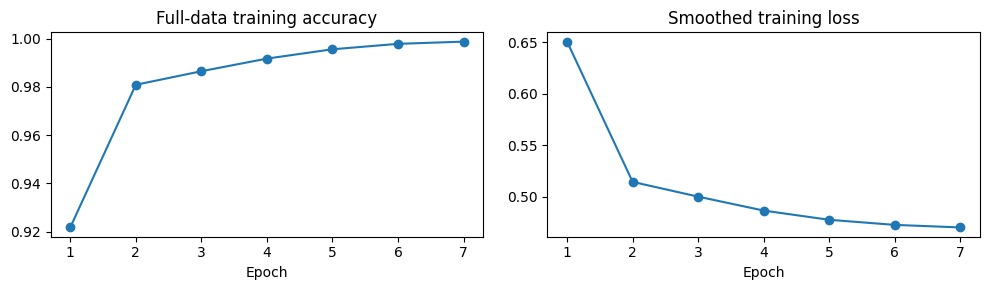

control_128: test inference (clean); progress is shown below.


control_128 test clean:   0%|          | 0/231 [00:00<?, ?it/s]

control_128: test inference (tta); progress is shown below.


control_128 test tta:   0%|          | 0/231 [00:00<?, ?it/s]

SAVED: /kaggle/working/full_data_pair_128/control_128_full_seed42

START geometry_128: all 63,645 labelled images; 7 epochs.
No validation score will be reported for this full-data model.


...

{'epoch': 5, 'train_loss': 0.48051990953944484, 'train_acc': 0.9941079424935187, 'skipped_updates': 4, 'seconds': 154.7}


geometry_128_full_seed42 epoch 6/7:   0%|          | 0/498 [00:00<?, ?it/s]

{'epoch': 6, 'train_loss': 0.47293768629919886, 'train_acc': 0.9972817974703433, 'skipped_updates': 4, 'seconds': 167.8}


geometry_128_full_seed42 epoch 7/7:   0%|          | 0/498 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.47117365952260704, 'train_acc': 0.9982559509780815, 'skipped_updates': 4, 'seconds': 295.9}
Loaded checkpoint epoch 7


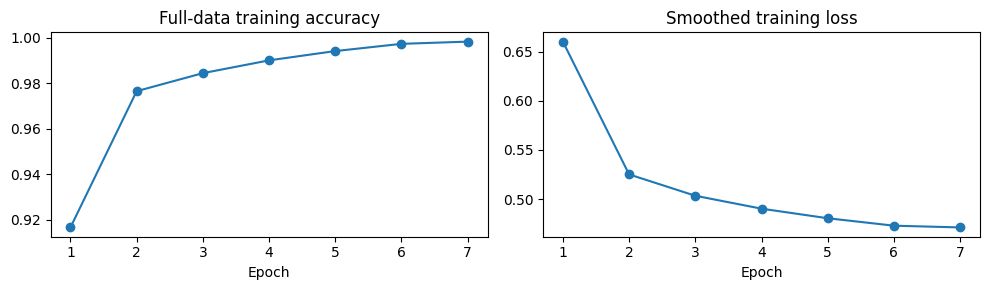

geometry_128: test inference (clean); progress is shown below.


geometry_128 test clean:   0%|          | 0/231 [00:00<?, ?it/s]

geometry_128: test inference (tta); progress is shown below.


geometry_128 test tta:   0%|          | 0/231 [00:00<?, ?it/s]

SAVED: /kaggle/working/full_data_pair_128/geometry_128_full_seed42

COMPLETE. Download and share: /kaggle/working/full_data_pair_128_backup.zip
Keep the 0.9793 submission as the benchmark. No Kaggle submission was made.


In [11]:
# Run this as ONE NEW CELL at the bottom of your completed Notebook 4.
# Keep that Kaggle session alive. Do not Run All: the audits are already done.
from pathlib import Path
import json, shutil, copy
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

needed = ['df','train_df','val_df','sample','CLASSES','COMMON','EXPERIMENTS',
          'fit','loader_for','predict','save_probabilities','save_submission',
          'FULL_DATA','FULL_EPOCHS','OUT','TRAIN_SEED','TRAIN_DIR','TEST_DIR']
missing = [name for name in needed if name not in globals()]
assert not missing, f'Use the completed Notebook 4 session. Missing: {missing}'
assert torch.cuda.is_available(), 'Keep the GPU enabled.'
assert len(df) == 63645 and df.image_id.is_unique
assert set(df.image_id) == set(train_df.image_id) | set(val_df.image_id)
assert set(train_df.image_id).isdisjoint(set(val_df.image_id))
assert len(sample) == 29443 and sample.image_id.is_unique
assert set(df['class']) == set(CLASSES)

FULL_ROOT = Path('/kaggle/working/full_data_pair_128')
assert not FULL_ROOT.exists(), (
    f'{FULL_ROOT} already exists. Preserve its contents; do not overwrite or rerun training blindly.')
FULL_ROOT.mkdir(parents=True)
# Seven epochs: the two split runs selected epochs 6 and 7 for each configuration.
# A fixed full-data budget is chosen in advance; no holdout metrics are computed.
plan = dict(training_images=len(df), epochs=7, training_seed=42,
            experiments=['control_128','geometry_128'],
            epoch_budget_reason='Validation-selected epochs were 6 and 7 across the two splits.',
            validation_metrics_available=False,
            benchmark_public_score=0.9793)
(FULL_ROOT/'training_plan.json').write_text(json.dumps(plan,indent=2))
df.to_csv(FULL_ROOT/'full_training_metadata.csv',index=False)

previous = dict(FULL_DATA=FULL_DATA, FULL_EPOCHS=FULL_EPOCHS,
                OUT=OUT, TRAIN_SEED=TRAIN_SEED)
try:
    FULL_DATA = True
    FULL_EPOCHS = 7
    TRAIN_SEED = 42
    OUT = FULL_ROOT
    for name in plan['experiments']:
        run_dir = FULL_ROOT/f'{name}_full_seed42'
        run_dir.mkdir()
        cfg = {**COMMON, **EXPERIMENTS[name]}
        print(f'\nSTART {name}: all {len(df):,} labelled images; {FULL_EPOCHS} epochs.',flush=True)
        print('No validation score will be reported for this full-data model.',flush=True)
        model,cfg,hist = fit(cfg,run_dir)
        assert cfg['full_data'] is True and cfg['split_hash'] is None
        assert not any(c.startswith('val_') for c in hist.columns)
        fig,axs = plt.subplots(1,2,figsize=(10,3))
        axs[0].plot(hist.epoch,hist.train_acc,'o-')
        axs[0].set_title('Full-data training accuracy');axs[0].set_xlabel('Epoch')
        axs[1].plot(hist.epoch,hist.train_loss,'o-')
        axs[1].set_title('Smoothed training loss');axs[1].set_xlabel('Epoch')
        plt.tight_layout();fig.savefig(run_dir/'learning_curves.png',dpi=140)
        plt.show();plt.close(fig)
        test_loader = loader_for(sample[['image_id']],TEST_DIR,cfg)
        for view,flip in [('clean',False),('tta',True)]:
            print(f'{name}: test inference ({view}); progress is shown below.',flush=True)
            p,_,ids = predict(model,tqdm(test_loader,desc=f'{name} test {view}'),flip=flip)
            assert np.array_equal(ids,sample.image_id.to_numpy())
            assert p.shape == (len(sample),len(CLASSES)) and np.isfinite(p).all()
            assert np.allclose(p.sum(1),1,atol=1e-5)
            save_probabilities(run_dir/f'test_{view}.npz',p,ids)
            save_submission(run_dir/f'submission_{view}.csv',p,ids)
        del test_loader,model
        torch.cuda.empty_cache()
        print('SAVED:',run_dir,flush=True)
    archive = shutil.make_archive(str(FULL_ROOT.parent/'full_data_pair_128_backup'),
                                  'zip',str(FULL_ROOT.parent),FULL_ROOT.name)
    print('\nCOMPLETE. Download and share:',archive,flush=True)
    print('Keep the 0.9793 submission as the benchmark. No Kaggle submission was made.',flush=True)
finally:
    # Restore Notebook 4 state; previous holdout outputs remain separate.
    FULL_DATA=previous['FULL_DATA']; FULL_EPOCHS=previous['FULL_EPOCHS']
    OUT=previous['OUT']; TRAIN_SEED=previous['TRAIN_SEED']


START: one ConvNeXt V2 candidate, 8 epochs, saved split 1337.
First use downloads new pretrained weights. Internet must be enabled.


model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

convnextv2_tiny_192_geometry_val1337_seed42 epoch 1/8:   0%|          | 0/846 [00:00<?, ?it/s]

Predict original:   0%|          | 0/150 [00:00<?, ?it/s]

...

Predict original:   0%|          | 0/150 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.47190343739122703, 'train_acc': 0.9979296831675848, 'skipped_updates': 5, 'seconds': 385.4, 'val_acc': 0.996438671834084, 'val_nll': 0.10221177266600984, 'val_errors': 34}


convnextv2_tiny_192_geometry_val1337_seed42 epoch 8/8:   0%|          | 0/846 [00:00<?, ?it/s]

Predict original:   0%|          | 0/150 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.4697101712105671, 'train_acc': 0.9988169618100484, 'skipped_updates': 5, 'seconds': 385.7, 'val_acc': 0.9954959673195768, 'val_nll': 0.10369250568177082, 'val_errors': 43}
Loaded checkpoint epoch 7


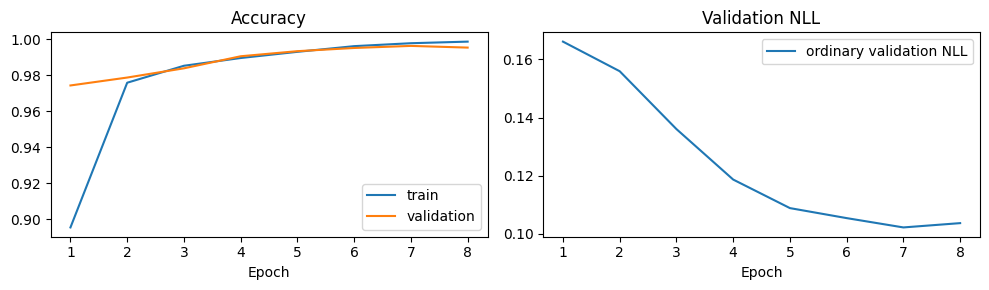

VALIDATION: clean


Predict original:   0%|          | 0/150 [00:00<?, ?it/s]

VALIDATION: tta


Predict original + flip:   0%|          | 0/150 [00:00<?, ?it/s]

VALIDATION: wide


...

Validation results saved. Generating labelled-ID-free test probabilities for later review.
TEST INFERENCE: clean


Predict original:   0%|          | 0/461 [00:00<?, ?it/s]

TEST INFERENCE: tta


Predict original + flip:   0%|          | 0/461 [00:00<?, ?it/s]


COMPLETE. Download and share: /kaggle/working/convnextv2_192_validation_backup.zip
No submission file was selected. Keep the 0.9801 benchmark.


In [12]:

# Run ONLY this new cell. Keep the existing Competition input and enable Internet/GPU.
# This validates ONE new candidate; it does not train on all data or submit to Kaggle.
from pathlib import Path
import json, hashlib, shutil
import numpy as np
import pandas as pd
import torch
import timm
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

required=['df','train_df','val_df','sample','CLASSES','COMMON','fit','loader_for',
          'predict','save_probabilities','save_submission','FULL_DATA','FULL_EPOCHS',
          'OUT','TRAIN_SEED','SPLIT_SEED','BATCH_SIZE','TRAIN_DIR','TEST_DIR','split_hash']
missing=[k for k in required if k not in globals()]
assert not missing, f'Use the completed Notebook 4 session. Missing: {missing}'
assert torch.cuda.is_available(), 'Enable a GPU.'
assert SPLIT_SEED==1337 and len(val_df)==9547
assert set(train_df.image_id).isdisjoint(set(val_df.image_id))
assert len(train_df)==54098 and len(df)==63645
assert hashlib.sha256(val_df.image_id.to_numpy(dtype='<i8').tobytes()).hexdigest()==split_hash
assert split_hash=='842af9ee7beb6fe8c85fd55163deeb15cf8a5c778506c075f987e9b9ed9889b6'

REFERENCE_ROOT=Path(OUT)
NEW_ROOT=Path('/kaggle/working/convnextv2_192_validation')
assert not NEW_ROOT.exists(), f'{NEW_ROOT} already exists; preserve its outputs before considering another run.'
assert 'convnextv2_tiny.fcmae_ft_in1k' in timm.list_models(pretrained=True), 'Model name not available in this timm version.'
y=val_df.label.to_numpy()
val_ids=val_df.image_id.to_numpy()

def _load_reference(model,view):
    path=REFERENCE_ROOT/f'{model}_128_val1337_seed42'/f'val_{view}.npz'
    assert path.is_file(), f'Missing confirmation output: {path}'
    with np.load(path,allow_pickle=False) as a:
        assert a['classes'].tolist()==CLASSES
        assert np.array_equal(a['image_id'],val_ids) and np.array_equal(a['labels'],y)
        assert str(a['split_hash'])==split_hash
        p=a['probs'].copy()
    assert np.isfinite(p).all() and np.allclose(p.sum(1),1,atol=1e-5)
    return p

def _validation_score(p):
    return dict(errors=int((p.argmax(1)!=y).sum()),
                accuracy=float((p.argmax(1)==y).mean()),
                nll=float(-np.log(p[np.arange(len(y)),y].clip(1e-12,1)).mean()))

# Validate the existing reference files BEFORE spending GPU time.
references={view:{model:_load_reference(model,view) for model in ['control','geometry']}
            for view in ['clean','tta','wide','tall']}
assert _validation_score(references['clean']['control'])['errors']==26
assert _validation_score(references['clean']['geometry'])['errors']==33

NEW_ROOT.mkdir(parents=True)
run_dir=NEW_ROOT/'convnextv2_tiny_192_geometry_val1337_seed42';run_dir.mkdir()
plan=dict(model='convnextv2_tiny.fcmae_ft_in1k',input_size=192,geometry=True,
          epochs=8,batch_size=64,training_seed=42,split_seed=1337,
          benchmark_public_score=.9801,
          purpose='Validate a new candidate for model diversity before any submission.',
          comparison_limit='Architecture, resolution and batch size differ; this is not an isolated architecture ablation.',
          model_reference='https://huggingface.co/timm/convnextv2_tiny.fcmae_ft_in1k')
(NEW_ROOT/'experiment_plan.json').write_text(json.dumps(plan,indent=2))
val_df[['image_id','class']].to_csv(NEW_ROOT/'val_split_1337.csv',index=False)

previous=dict(FULL_DATA=FULL_DATA,FULL_EPOCHS=FULL_EPOCHS,OUT=OUT,
              TRAIN_SEED=TRAIN_SEED,BATCH_SIZE=BATCH_SIZE,predict=predict)
_original_predict=predict

def _predict_visible(model,loader,flip=False,_impl=_original_predict):
    label='Predict original + flip' if flip else 'Predict original'
    return _impl(model,tqdm(loader,desc=label,leave=False),flip=flip)

try:
    FULL_DATA=False;FULL_EPOCHS=None;OUT=NEW_ROOT;TRAIN_SEED=42;BATCH_SIZE=64
    # Both epoch evaluation and final prediction now display progress.
    predict=_predict_visible
    cfg={**COMMON,'model':plan['model'],'size':192,'geometry':True,'epochs':8,'batch_size':64}
    print('START: one ConvNeXt V2 candidate, 8 epochs, saved split 1337.',flush=True)
    print('First use downloads new pretrained weights. Internet must be enabled.',flush=True)
    model,cfg,hist=fit(cfg,run_dir)
    assert not cfg['full_data'] and cfg['split_hash']==split_hash
    fig,axs=plt.subplots(1,2,figsize=(10,3))
    axs[0].plot(hist.epoch,hist.train_acc,label='train')
    axs[0].plot(hist.epoch,hist.val_acc,label='validation');axs[0].legend()
    axs[0].set_title('Accuracy');axs[0].set_xlabel('Epoch')
    axs[1].plot(hist.epoch,hist.val_nll,label='ordinary validation NLL');axs[1].legend()
    axs[1].set_title('Validation NLL');axs[1].set_xlabel('Epoch')
    plt.tight_layout();fig.savefig(run_dir/'learning_curves.png',dpi=140);plt.show();plt.close(fig)
    from sklearn.metrics import classification_report,confusion_matrix
    results=[];new_val={}
    for view in ['clean','tta','wide','tall']:
        print('VALIDATION:',view,flush=True)
        loader=loader_for(val_df,TRAIN_DIR,cfg,stress=view if view in ['wide','tall'] else None)
        p,labels_out,ids=predict(model,loader,flip=view=='tta')
        assert np.array_equal(ids,val_ids) and np.array_equal(labels_out,y)
        save_probabilities(run_dir/f'val_{view}.npz',p,ids,y)
        new_val[view]=p
        for name,probs in [('control_128',references[view]['control']),
                           ('geometry_128',references[view]['geometry']),('convnextv2_192',p)]:
            results.append(dict(model=name,view=view,**_validation_score(probs)))
        if view=='clean':
            report=classification_report(y,p.argmax(1),labels=range(len(CLASSES)),
                                         target_names=CLASSES,digits=5,zero_division=0)
            (run_dir/'classification_report.txt').write_text(report)
            pd.DataFrame(confusion_matrix(y,p.argmax(1),labels=range(len(CLASSES))),
                         index=CLASSES,columns=CLASSES).to_csv(run_dir/'confusion_matrix.csv')
            errors=val_df.copy();errors['pred_class']=np.array(CLASSES)[p.argmax(1)]
            errors[errors['class']!=errors.pred_class].to_csv(run_dir/'validation_errors.csv',index=False)
        del loader
    result_table=pd.DataFrame(results)
    result_table.to_csv(NEW_ROOT/'candidate_validation_results.csv',index=False)
    display(result_table.pivot(index='model',columns='view',values=['errors','accuracy']))

    # A small prespecified comparison on the same held-out IDs, never on training images.
    # No old split-42 ensemble is evaluated on this entire split: it trained on many of these IDs.
    blend_rows=[]
    for view in ['clean','tta']:
        reference=.75*references[view]['control']+.25*references[view]['geometry']
        base_pred=reference.argmax(1)
        for w in [0,.25,.5,1.]:
            p=(1-w)*reference+w*new_val[view]
            pred=p.argmax(1)
            blend_rows.append(dict(view=view,new_model_weight=w,**_validation_score(p),
                                   fixed=int(((base_pred!=y)&(pred==y)).sum()),
                                   broken=int(((base_pred==y)&(pred!=y)).sum())))
    blend_table=pd.DataFrame(blend_rows)
    blend_table.to_csv(NEW_ROOT/'same_split_blend_comparison.csv',index=False)
    display(blend_table)
    print('Validation results saved. Generating labelled-ID-free test probabilities for later review.',flush=True)
    test_loader=loader_for(sample[['image_id']],TEST_DIR,cfg)
    for view,flip in [('clean',False),('tta',True)]:
        print('TEST INFERENCE:',view,flush=True)
        p,_,ids=predict(model,test_loader,flip=flip)
        assert np.array_equal(ids,sample.image_id.to_numpy())
        assert p.shape==(len(sample),len(CLASSES)) and np.isfinite(p).all()
        assert np.allclose(p.sum(1),1,atol=1e-5)
        save_probabilities(run_dir/f'test_{view}.npz',p,ids)
        # Save probabilities only. Choose any submission after reviewing validation.
    del test_loader,model;torch.cuda.empty_cache()
    archive=shutil.make_archive(str(NEW_ROOT.parent/'convnextv2_192_validation_backup'),
                                'zip',str(NEW_ROOT.parent),NEW_ROOT.name)
    print('\nCOMPLETE. Download and share:',archive,flush=True)
    print('No submission file was selected. Keep the 0.9801 benchmark.',flush=True)
finally:
    FULL_DATA=previous['FULL_DATA'];FULL_EPOCHS=previous['FULL_EPOCHS'];OUT=previous['OUT']
    TRAIN_SEED=previous['TRAIN_SEED'];BATCH_SIZE=previous['BATCH_SIZE'];predict=previous['predict']
